[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/data-engineering-from-scratch-to-advanced/blob/main/notebooks/topics/21_data-for-ai.ipynb)

*Data Engineering from Scratch to Advanced · Notebook 21 of 21*

# Data Engineering for AI

The data behind models and LLMs: feature stores and point-in-time joins, leakage, dataset versioning, RAG ingestion pipelines, incremental embedding, deduplication, PII scrubbing and evaluation data. It's a bridge from data engineering to AI engineering.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** A model is only as good as its data pipeline. Everything you've learned applies, with leakage and freshness as the new traps.

**What interviewers really test here:** Point-in-time correctness, feature stores, RAG ingestion and keeping indexes fresh.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. AI runs on data pipelines *(Basics)*
- [ ] 2. Reliable training data *(Core)*
- [ ] 3. A RAG ingestion pipeline *(Core)*
- [ ] 4. Quality, privacy and feedback for AI data *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Your path from data engineer to AI engineer

| You already know | It becomes |
| --- | --- |
| Incremental loads and hashing | incremental embedding |
| Data quality tests | LLM and model evaluation |
| SCD 2 and point-in-time joins | leakage-free training data |
| Orchestration | training and ingestion pipelines |
| Streaming | real-time features |
| Access control | permission-aware retrieval |

---
# Part 2: Lessons, step by step

## Lesson 1: AI runs on data pipelines

*Level: Basics*

This is your bridge from data engineering to AI engineering. Models get the attention, but most production AI problems are data problems.



| AI system | What the data engineer builds |
| --- | --- |
| Classic ML | feature pipelines, training sets, feature stores |
| RAG / LLM apps | ingestion, chunking, embedding, keeping indexes fresh |
| Fine-tuning | clean, deduplicated, versioned training data |
| Evaluation | eval sets, logging, feedback loops |



**Skills you already have from this course apply directly:** idempotency, incremental loads, data quality, lineage and cost control.



**Rule one of training data: never leak the future.** A model predicting churn in January mustn't see February's data. This is the same point-in-time idea as SCD 2.



| Label | Feature history for a | Correct value |
| --- | --- | --- |
| a at time 10 | t5: 1, t20: 2, t30: 3 | **1** |
| a at time 25 | same | **2** |
| b at time 5 | t9: 7 | **None**: it didn't exist yet |



A naive join on the latest value would give every label 3, and 2 of the 3 labels would see the future. The model looks brilliant in testing and fails in production.



**Rolling features** must exclude the present: "spend in the previous 7 days" for days 1, 2, 9, 10 with amounts 10, 20, 5, 1 gives 0, 10, 20, 5.

**✏️ Your turn:** you now have what you need for [Q19](#q19), [Q6](#q6), [Q7](#q7). Try one now, or carry on and do them in Part 3.

## Lesson 2: Reliable training data

*Level: Core*

**Stable splits.** Random splits change on each run, and the same user can land in both train and test. Hash the id instead: `md5(id) % 100 < 20` always puts a user in the same set, and new data doesn't shuffle old assignments.



**Version your datasets.** "Which data trained this model?" should have an exact answer. A content hash that doesn't depend on row order works, and tools like Iceberg snapshots or DVC can help.



**Check before training:**



| Check | Example |
| --- | --- |
| Label balance | a 75%, b 25%; is the minority too rare? |
| Duplicates | the same question twice leaks across a split |
| Eval isolation | id "a" in both eval and training is a leak |
| Missing answers | an eval case with no expected answer is useless |



**Feature stores** solve training-serving skew. A feature is defined once, and it's served offline for training (point in time) and online with low latency. Compare both regularly: key c missing online, and b at 2.0 vs 2.5, are both bugs that crash nothing but hurt the model.



**Training files** are often JSON Lines of messages. Clean them like any data: of 3 pairs here, one empty and one duplicate leave a single valid example.

**✏️ Your turn:** you now have what you need for [Q8](#q8), [Q9](#q9), [Q1](#q1), [Q15](#q15), [Q16](#q16), [Q14](#q14). Try one now, or carry on and do them in Part 3.

## Lesson 3: A RAG ingestion pipeline

*Level: Core*

A demo RAG app embeds a folder once. A production one is a **data pipeline that never stops**, since documents change and get deleted.



```text
Sources → Load → Clean → Scrub PII → Chunk → Hash → Embed new only → Upsert → Delete removed
                                                        ↑
                                 stored hashes say what's changed
```



**Clean.** "&lt;p&gt;Hello &lt;b&gt;world&lt;/b&gt; today&lt;/p&gt;" becomes "Hello world today". Navigation menus and boilerplate hurt retrieval, so strip them.



**Chunk.** With size 3 and overlap 1, "a b c d e f g" gives "a b c", "c d e", "e f g". Keep titles with chunks, and test sizes on your own questions.



**Incremental embedding is where this course pays off.** Hash each chunk, and compare with what's stored:



| Chunk | State | Action |
| --- | --- | --- |
| a: unchanged | hash matches | skip: saves money |
| b: edited | hash differs | re-embed |
| c: new | no stored hash | embed |
| d: gone | not in source | **delete**, or answers cite dead documents |



**Cost.** 1 million documents of 500 tokens at a made-up 0.10 per million tokens costs 50, and takes 2.78 hours at 50,000 tokens a second. Batch within both limits, and set aside anything too large.



**Model upgrades.** Vectors from different models can't be compared, so changing the model means re-embedding everything. Store the model name with each vector. An index with mixed models isn't safe to query.



**Freshness.** If one of three documents changed after being indexed, 33% of your index is stale. Alert on that, as you would with any table.

**✏️ Your turn:** you now have what you need for [Q2](#q2), [Q3](#q3), [Q10](#q10), [Q4](#q4), [Q11](#q11), [Q17](#q17), [Q5](#q5). Try one now, or carry on and do them in Part 3.

## Lesson 4: Quality, privacy and feedback for AI data

*Level: Advanced*

**Near-duplicates waste money and crowd out useful results.** Word-set Jaccard similarity finds them: "the cat sat here" and "the cat sat there" share 3 of 5 words, 0.6.



Comparing all pairs is impossible at scale, so **MinHash** estimates similarity using small signatures: the chance that two sets share a minimum hash equals their Jaccard similarity. Our test with 200 hashes estimates 0.59, against a true 0.60. Combined with locality-sensitive hashing, it finds likely matches without comparing everything.



The chart shows how the estimate settles as hashes are added.



**Scrub personal data before embedding or training.** Once it's in a vector index, or worse a trained model, removing it is hard or impossible. "Mail a@b.io or call 9876543210" becomes "Mail [EMAIL] or call [PHONE]". Simple patterns miss a lot, so use dedicated tools on real data, and apply access control at retrieval time too.



**Close the loop.** Log which sources were retrieved, and whether answers helped. A source used twice with 0% helpfulness is a data problem you can fix. Requiring a minimum number of uses avoids judging from one example.



**Where to go next as an AI engineer:**



- Vector databases and hybrid search.
- Evaluation pipelines for LLM apps.
- Data contracts for AI features.
- Streaming features for real-time models.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

true: 0.333 estimate at 400: 0.347


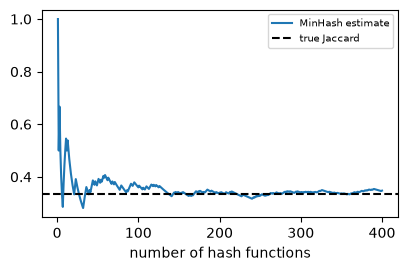

In [2]:
import hashlib


def minhash_convergence():
    a = {f"w{i}" for i in range(100)}
    b = {f"w{i}" for i in range(50, 150)}
    true = len(a & b) / len(a | b)
    h = lambda i, w: hashlib.md5(f"{i}{w}".encode()).hexdigest()
    hits = [min(h(i, w) for w in a) == min(h(i, w) for w in b) for i in range(400)]
    estimates = np.cumsum(hits) / np.arange(1, 401)
    print("true:", round(true, 3), "estimate at 400:", round(float(estimates[-1]), 3))
    fig, ax = plt.subplots(figsize=(4.6, 2.7))
    ax.plot(range(1, 401), estimates, label="MinHash estimate")
    ax.axhline(true, color="black", linestyle="--", label="true Jaccard")
    ax.set_xlabel("number of hash functions")
    ax.legend(fontsize=7)


minhash_convergence()

**✏️ Your turn:** you now have what you need for [Q12](#q12), [Q20](#q20), [Q13](#q13), [Q18](#q18). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [3]:
from collections import Counter, defaultdict

import re

import hashlib

import json


<a id="q1"></a>
### Q1. Label Balance

🟢 Warm-up · *Know your classes*

Return each label's share, rounded to 3 decimals and sorted, and whether the rarest is below min\_share.

**Examples**

- `labels = ['a', 'a', 'a', 'b'], min_share = 0.3` → `({'a': 0.75, 'b': 0.25}, True)`

In [ ]:
def label_balance(labels, min_share):
    """
    Return each label's share, rounded to 3 decimals and sorted, and whether the
    rarest is below min_share.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(label_balance, [
    ((['a', 'a', 'a', 'b'], 0.3), ({'a': 0.75, 'b': 0.25}, True)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A dictionary.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`Counter`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A dictionary.

```python
def label_balance(labels, min_share):
    counts = {}
    for l in labels:
        counts[l] = counts.get(l, 0) + 1
    shares = {k: round(counts[k] / len(labels), 3) for k in sorted(counts)}
    return (shares, min(shares.values()) < min_share)
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `Counter`.

```python
def label_balance(labels, min_share):
    s = {k: round(v / len(labels), 3) for k, v in sorted(Counter(labels).items())}
    return (s, min(s.values()) < min_share)
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A dictionary. That costs O(n) time and O(k) space."

"I can do better: `Counter`. That's O(n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-for-ai/label-balance)

<a id="q2"></a>
### Q2. Clean Text for Ingestion

🟢 Warm-up · *Garbage in, garbage out*

Strip HTML tags, collapse whitespace, and drop documents under min\_words. Return cleaned documents.

**Examples**

- `docs = ['<p>Hello   <b>world</b> today</p>', '<div>hi</div>'], min_words = 2` → `['Hello world today']`

In [ ]:
def clean_docs(docs, min_words):
    """
    Strip HTML tags, collapse whitespace, and drop documents under min_words.
    Return cleaned documents.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(clean_docs, [
    ((['<p>Hello   <b>world</b> today</p>', '<div>hi</div>'], 2), ['Hello world today']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Walk characters, tracking whether inside a tag.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Regular expressions. Real HTML is better parsed by a library.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Walk characters, tracking whether inside a tag.

```python
def clean_docs(docs, min_words):
    out = []
    for d in docs:
        text, inside = "", False
        for ch in d:
            if ch == "<":
                inside = True
            elif ch == ">":
                inside = False
            elif not inside:
                text += ch
        words = text.split()
        if len(words) >= min_words:
            out.append(" ".join(words))
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Regular expressions. Real HTML is better parsed by a library.

```python
def clean_docs(docs, min_words):
    clean = (" ".join(re.sub(r"<[^>]+>", "", d).split()) for d in docs)
    return [c for c in clean if len(c.split()) >= min_words]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Walk characters, tracking whether inside a tag. That costs O(n) time and O(n) space."

"I can do better: Regular expressions. Real HTML is better parsed by a library. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-for-ai/clean-text-for-ingestion)

<a id="q3"></a>
### Q3. Chunk With Overlap

🟢 Warm-up · *Splitting for retrieval*

Split words into chunks of size words, stepping by size − overlap. Return chunks as strings.

**Examples**

- `text = 'a b c d e f g', size = 3, overlap = 1` → `['a b c', 'c d e', 'e f g']`

In [ ]:
def chunk_text(text, size, overlap):
    """
    Split words into chunks of size words, stepping by size − overlap. Return
    chunks as strings.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(chunk_text, [
    (('a b c d e f g', 3, 1), ['a b c', 'c d e', 'e f g']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A while loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A comprehension with a step.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A while loop.

```python
def chunk_text(text, size, overlap):
    words = text.split()
    out, i = [], 0
    while True:
        out.append(" ".join(words[i:i + size]))
        if i + size >= len(words):
            break
        i += size - overlap
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A comprehension with a step.

```python
def chunk_text(text, size, overlap):
    w, step = text.split(), size - overlap
    n = max(0, math.ceil((len(w) - size) / step)) + 1
    return [" ".join(w[i * step:i * step + size]) for i in range(n)]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A while loop. That costs O(n) time and O(n) space."

"I can do better: A comprehension with a step. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-for-ai/chunk-with-overlap)

<a id="q4"></a>
### Q4. Embedding Cost and Time

🟢 Warm-up · *Plan the backfill*

Given documents, tokens per document, a made-up price per million tokens and tokens per second, return cost and hours, rounded to 2 decimals.

**Examples**

- `docs = 1000000, tokens = 500, price = 0.1, rate = 50000` → `(50.0, 2.78)`

In [ ]:
def embed_cost(docs, tokens, price, rate):
    """
    Given documents, tokens per document, a made-up price per million tokens and
    tokens per second, return cost and hours, rounded to 2 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(embed_cost, [
    ((1000000, 500, 0.1, 50000), (50.0, 2.78)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Step by step.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Compact.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Step by step.

```python
def embed_cost(docs, tokens, price, rate):
    total = docs * tokens
    cost = total / 1e6 * price
    hours = total / rate / 3600
    return (round(cost, 2), round(hours, 2))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Compact.

```python
def embed_cost(docs, tokens, price, rate):
    t = docs * tokens
    return (round(t * price / 1e6, 2), round(t / rate / 3600, 2))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Step by step. That costs O(1) time and O(1) space."

"I can do better: Compact. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-for-ai/embedding-cost-and-time)

<a id="q5"></a>
### Q5. Freshness of a Vector Index

🟢 Warm-up · *Is the answer out of date?*

Given each document's last update and last index time, return stale ids, sorted, and the percent stale, rounded to 1 decimal.

**Examples**

- `docs = {'a': (10, 12), 'b': (20, 15), 'c': (5, 5)}` → `(['b'], 33.3)`

In [ ]:
def stale_docs(docs):
    """
    Given each document's last update and last index time, return stale ids,
    sorted, and the percent stale, rounded to 1 decimal.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(stale_docs, [
    (({'a': (10, 12), 'b': (20, 15), 'c': (5, 5)},), (['b'], 33.3)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A sorted comprehension.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop.

```python
def stale_docs(docs):
    out = []
    for k, (updated, indexed) in docs.items():
        if updated > indexed:
            out.append(k)
    return (sorted(out), round(100 * len(out) / len(docs), 1))
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A sorted comprehension.

```python
def stale_docs(docs):
    s = sorted(k for k, (u, i) in docs.items() if u > i)
    return (s, round(100 * len(s) / len(docs), 1))
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop. That costs O(n log n) time and O(n) space."

"I can do better: A sorted comprehension. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-for-ai/freshness-of-a-vector-index)

<a id="q6"></a>
### Q6. What a Leak Looks Like

🟡 Interview standard · *Too good to be true*

Compare a naive join (latest value overall) to a point-in-time one. Return how many labels would see a future value.

**Examples**

- `labels = [('a', 10), ('a', 25), ('b', 5)], latest_time = {'a': 30, 'b': 3}` → `2`

In [ ]:
def leaked_labels(labels, latest_time):
    """
    Compare a naive join (latest value overall) to a point-in-time one. Return
    how many labels would see a future value.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(leaked_labels, [
    (([('a', 10), ('a', 25), ('b', 5)], {'a': 30, 'b': 3}), 2),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A generator.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop.

```python
def leaked_labels(labels, latest_time):
    count = 0
    for user, t in labels:
        if latest_time[user] > t:
            count += 1
    return count
```

**Cost:** O(l) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A generator.

```python
def leaked_labels(labels, latest_time):
    return sum(latest_time[u] > t for u, t in labels)
```

**Cost:** O(l) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop. That costs O(l) time and O(1) space."

"I can do better: A generator. That's O(l) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-for-ai/what-a-leak-looks-like)

<a id="q7"></a>
### Q7. Rolling Feature

🟡 Interview standard · *Spend in the last 7 days*

For each (day, amount) row in order, return the sum of amounts in the previous w days, excluding today, as training must not see the present value.

**Examples**

- `rows = [(1, 10), (2, 20), (9, 5), (10, 1)], w = 7` → `[0, 10, 20, 5]`

In [ ]:
def rolling_feature(rows, w):
    """
    For each (day, amount) row in order, return the sum of amounts in the
    previous w days, excluding today, as training must not see the present
    value.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(rolling_feature, [
    (([(1, 10), (2, 20), (9, 5), (10, 1)], 7), [0, 10, 20, 5]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Rescan for each row.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A deque for the sliding window.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Rescan for each row.

```python
def rolling_feature(rows, w):
    out = []
    for day, _ in rows:
        out.append(sum(a for d, a in rows if day - w <= d < day))
    return out
```

**Cost:** O(n²) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A deque for the sliding window.

```python
def rolling_feature(rows, w):
    from collections import deque
    win, total, out = deque(), 0, []
    for day, amount in rows:
        while win and win[0][0] < day - w:
            total -= win.popleft()[1]
        out.append(total)
        win.append((day, amount))
        total += amount
    return out
```

**Cost:** O(n) time, O(w) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Rescan for each row. That costs O(n²) time and O(1) space."

"I can do better: A deque for the sliding window. That's O(n) time and O(w) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-for-ai/rolling-feature)

<a id="q8"></a>
### Q8. Stable Train/Test Split

🟡 Interview standard · *Same split every run*

Assign by hash: md5(id) as an integer, mod 100, below test\_pct goes to test. Random splits change between runs, and leak users across sets. Return (train ids, test ids).

**Examples**

- `ids = ['u1', 'u2', 'u3', 'u4', 'u5', 'u6'], test_pct = 34` → `(['u2', 'u4', 'u6'], ['u1', 'u3', 'u5'])`

In [ ]:
def stable_split(ids, test_pct):
    """
    Assign by hash: md5(id) as an integer, mod 100, below test_pct goes to test.
    Random splits change between runs, and leak users across sets. Return (train
    ids, test ids).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(stable_split, [
    ((['u1', 'u2', 'u3', 'u4', 'u5', 'u6'], 34), (['u2', 'u4', 'u6'], ['u1', 'u3', 'u5'])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A helper in comprehensions.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop.

```python
def stable_split(ids, test_pct):
    train, test = [], []
    for i in ids:
        bucket = int(hashlib.md5(i.encode()).hexdigest(), 16) % 100
        if bucket < test_pct:
            test.append(i)
        else:
            train.append(i)
    return (train, test)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A helper in comprehensions.

```python
def stable_split(ids, test_pct):
    is_test = lambda i: int(hashlib.md5(i.encode()).hexdigest(), 16) % 100 < test_pct
    return ([i for i in ids if not is_test(i)], [i for i in ids if is_test(i)])
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop. That costs O(n) time and O(n) space."

"I can do better: A helper in comprehensions. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-for-ai/stable-train-test-split)

<a id="q9"></a>
### Q9. Version a Dataset

🟡 Interview standard · *Which data trained this model?*

Return a short content hash of rows that doesn't depend on row order: md5 of the sorted JSON lines, first 8 characters. Also return whether two orders give the same version.

**Examples**

- `rows = [{'a': 1}, {'a': 2}]` → `('1ba60f45', True)`

In [ ]:
def dataset_version(rows):
    """
    Return a short content hash of rows that doesn't depend on row order: md5 of
    the sorted JSON lines, first 8 characters. Also return whether two orders
    give the same version.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(dataset_version, [
    (([{'a': 1}, {'a': 2}],), ('1ba60f45', True)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Build the lines in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A helper used twice.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Build the lines in a loop.

```python
def dataset_version(rows):
    lines = []
    for r in rows:
        lines.append(json.dumps(r, sort_keys=True))
    lines.sort()
    v1 = hashlib.md5("\n".join(lines).encode()).hexdigest()[:8]
    lines2 = sorted(json.dumps(r, sort_keys=True) for r in reversed(rows))
    v2 = hashlib.md5("\n".join(lines2).encode()).hexdigest()[:8]
    return (v1, v1 == v2)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A helper used twice.

```python
def dataset_version(rows):
    v = lambda x: hashlib.md5("\n".join(sorted(json.dumps(r, sort_keys=True) for r in x)).encode()).hexdigest()[:8]
    return (v(rows), v(rows) == v(rows[::-1]))
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Build the lines in a loop. That costs O(n log n) time and O(n) space."

"I can do better: A helper used twice. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-for-ai/version-a-dataset)

<a id="q10"></a>
### Q10. Embed Only What Changed

🟡 Interview standard · *Embeddings cost money*

Given stored {chunk\_id: hash} and current {chunk\_id: text}, return (ids to embed, ids to delete, ids unchanged), sorted. Hash = md5 of the text.

**Examples**

- `stored = {'a': 'f97c5d29941bfb1b2fdab0874906ab82', 'b': 'b8a9f715dbb64fd5c56e7783c6820a61'}, current = {'a': 'one', 'b': 'TWO', 'c': 'three'}` → `(['b', 'c'], [], ['a'])`

In [ ]:
def embed_plan(stored, current):
    """
    Given stored {chunk_id: hash} and current {chunk_id: text}, return (ids to
    embed, ids to delete, ids unchanged), sorted. Hash = md5 of the text.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(embed_plan, [
    (({'a': 'f97c5d29941bfb1b2fdab0874906ab82', 'b': 'b8a9f715dbb64fd5c56e7783c6820a61'}, {'a': 'one', 'b': 'TWO', 'c': 'three'}), (['b', 'c'], [], ['a'])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Sets and a comprehension.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Loops.

```python
def embed_plan(stored, current):
    embed, keep = [], []
    for k, text in current.items():
        if stored.get(k) == hashlib.md5(text.encode()).hexdigest():
            keep.append(k)
        else:
            embed.append(k)
    delete = [k for k in stored if k not in current]
    return (sorted(embed), sorted(delete), sorted(keep))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Sets and a comprehension.

```python
def embed_plan(stored, current):
    now = {k: hashlib.md5(t.encode()).hexdigest() for k, t in current.items()}
    same = {k for k in now if stored.get(k) == now[k]}
    return (sorted(now.keys() - same), sorted(stored.keys() - now.keys()), sorted(same))
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loops. That costs O(n) time and O(n) space."

"I can do better: Sets and a comprehension. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-for-ai/embed-only-what-changed)

<a id="q11"></a>
### Q11. Batch for an Embedding API

🟡 Interview standard · *Respect both limits*

Group token counts into batches with at most max\_items and max\_tokens each. A single item over max\_tokens goes to skipped. Return (batches, skipped).

**Examples**

- `counts = [100, 300, 900, 200, 2000], max_items = 2, max_tokens = 1000` → `([[100, 300], [900], [200]], [2000])`

In [ ]:
def embed_batches(counts, max_items, max_tokens):
    """
    Group token counts into batches with at most max_items and max_tokens each.
    A single item over max_tokens goes to skipped. Return (batches, skipped).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(embed_batches, [
    (([100, 300, 900, 200, 2000], 2, 1000), ([[100, 300], [900], [200]], [2000])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Grow a list, checking the sum.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A running total.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Grow a list, checking the sum.

```python
def embed_batches(counts, max_items, max_tokens):
    batches, cur, skipped = [], [], []
    for c in counts:
        if c > max_tokens:
            skipped.append(c)
            continue
        if cur and (len(cur) == max_items or sum(cur) + c > max_tokens):
            batches.append(cur)
            cur = []
        cur.append(c)
    if cur:
        batches.append(cur)
    return (batches, skipped)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A running total.

```python
def embed_batches(counts, max_items, max_tokens):
    batches, cur, total = [], [], 0
    for c in (x for x in counts if x <= max_tokens):
        if cur and (len(cur) == max_items or total + c > max_tokens):
            batches.append(cur)
            cur, total = [], 0
        cur.append(c)
        total += c
    return (batches + [cur] if cur else batches, [x for x in counts if x > max_tokens])
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Grow a list, checking the sum. That costs O(n) time and O(n) space."

"I can do better: A running total. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-for-ai/batch-for-an-embedding-api)

<a id="q12"></a>
### Q12. Near-Duplicate Documents

🟡 Interview standard · *Don't index ten copies*

Keep a document only if its word-set Jaccard similarity to every kept one is below limit. Return kept indexes.

**Examples**

- `docs = ['the cat sat here', 'the cat sat there', 'stock prices fell'], limit = 0.5` → `[0, 2]`

In [ ]:
def near_dupes(docs, limit):
    """
    Keep a document only if its word-set Jaccard similarity to every kept one is
    below limit. Return kept indexes.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(near_dupes, [
    ((['the cat sat here', 'the cat sat there', 'stock prices fell'], 0.5), [0, 2]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute overlaps with lists.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Precompute sets.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Compute overlaps with lists.

```python
def near_dupes(docs, limit):
    kept = []
    for i, d in enumerate(docs):
        a = set(d.split())
        dup = False
        for j in kept:
            b = set(docs[j].split())
            if len(a & b) / len(a | b) >= limit:
                dup = True
                break
        if not dup:
            kept.append(i)
    return kept
```

**Cost:** O(n²·w) time, O(w) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Precompute sets.

```python
def near_dupes(docs, limit):
    sets = [set(d.split()) for d in docs]
    kept = []
    for i, s in enumerate(sets):
        if all(len(s & sets[j]) / len(s | sets[j]) < limit for j in kept):
            kept.append(i)
    return kept
```

**Cost:** O(n²·w) time, O(n·w) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute overlaps with lists. That costs O(n²·w) time and O(w) space."

"I can do better: Precompute sets. That's O(n²·w) time and O(n·w) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-for-ai/near-duplicate-documents)

<a id="q13"></a>
### Q13. Scrub Personal Data

🟡 Interview standard · *Before embedding or training*

Replace emails and 10-digit numbers with placeholders, and count replacements. Once in a vector index or model, it's hard to remove.

**Examples**

- `text = 'Mail a@b.io or call 9876543210, or c@d.io'` → `('Mail [EMAIL] or call [PHONE], or [EMAIL]', 3)`

In [ ]:
def scrub(text):
    """
    Replace emails and 10-digit numbers with placeholders, and count
    replacements. Once in a vector index or model, it's hard to remove.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(scrub, [
    (('Mail a@b.io or call 9876543210, or c@d.io',), ('Mail [EMAIL] or call [PHONE], or [EMAIL]', 3)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Word by word.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`re.subn`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Word by word.

```python
def scrub(text):
    a = re.findall(r"\S+@\S+\.\w+", text)
    for x in a:
        text = text.replace(x, "[EMAIL]")
    b = re.findall(r"\b\d{10}\b", text)
    for x in b:
        text = text.replace(x, "[PHONE]")
    return (text, len(a) + len(b))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `re.subn`.

```python
def scrub(text):
    text, a = re.subn(r"\S+@\S+\.\w+", "[EMAIL]", text)
    text, b = re.subn(r"\b\d{10}\b", "[PHONE]", text)
    return (text, a + b)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Word by word. That costs O(n) time and O(n) space."

"I can do better: `re.subn`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-for-ai/scrub-personal-data)

<a id="q14"></a>
### Q14. Build a Training File

🟡 Interview standard · *JSON Lines for LLM evaluation or tuning*

Turn (question, answer) pairs into JSONL lines with messages, skipping empties and duplicate questions. Return (lines, skipped).

**Examples**

- `pairs = [('Hi?', 'Hello'), ('', 'x'), ('Hi?', 'Dup')]` → `(['{"messages": [{"role": "user", "content": "Hi?"}, {"role": "assistant", "content": "Hello"}]}'], 2)`

In [ ]:
def training_lines(pairs):
    """
    Turn (question, answer) pairs into JSONL lines with messages, skipping
    empties and duplicate questions. Return (lines, skipped).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(training_lines, [
    (([('Hi?', 'Hello'), ('', 'x'), ('Hi?', 'Dup')],), (['{"messages": [{"role": "user", "content": "Hi?"}, {"role": "assistant", "content": "Hello"}]}'], 2)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop with checks.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same, with a seen set and a helper.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop with checks.

```python
def training_lines(pairs):
    seen, lines, skipped = [], [], 0
    for q, a in pairs:
        if not q or not a or q in seen:
            skipped += 1
            continue
        seen.append(q)
        lines.append(json.dumps({"messages": [{"role": "user", "content": q}, {"role": "assistant", "content": a}]}))
    return (lines, skipped)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same, with a seen set and a helper.

```python
def training_lines(pairs):
    unique = {}
    for q, a in pairs:
        if q and a:
            unique.setdefault(q, a)
    msg = lambda q, a: json.dumps({"messages": [{"role": "user", "content": q}, {"role": "assistant", "content": a}]})
    return ([msg(q, a) for q, a in unique.items()], len(pairs) - len(unique))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop with checks. That costs O(n) time and O(n) space."

"I can do better: Same, with a seen set and a helper. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-for-ai/build-a-training-file)

<a id="q15"></a>
### Q15. Check an Eval Set

🟡 Interview standard · *Test data needs testing*

An eval set must have no overlap with the training ids, and every case needs an expected answer. Return (leaked ids sorted, ids with no answer sorted).

**Examples**

- `eval_set = {'a': 'x', 'b': '', 'c': 'y'}, train_ids = ['a', 'z']` → `(['a'], ['b'])`

In [ ]:
def check_eval(eval_set, train_ids):
    """
    An eval set must have no overlap with the training ids, and every case needs
    an expected answer. Return (leaked ids sorted, ids with no answer sorted).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(check_eval, [
    (({'a': 'x', 'b': '', 'c': 'y'}, ['a', 'z']), (['a'], ['b'])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A set.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Loops.

```python
def check_eval(eval_set, train_ids):
    leaked, empty = [], []
    for k, v in eval_set.items():
        if k in train_ids:
            leaked.append(k)
        if not v:
            empty.append(k)
    return (sorted(leaked), sorted(empty))
```

**Cost:** O(n·t) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A set.

```python
def check_eval(eval_set, train_ids):
    return (sorted(eval_set.keys() & set(train_ids)), sorted(k for k, v in eval_set.items() if not v))
```

**Cost:** O(n + t) time, O(t) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loops. That costs O(n·t) time and O(n) space."

"I can do better: A set. That's O(n + t) time and O(t) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-for-ai/check-an-eval-set)

<a id="q16"></a>
### Q16. Serving Features: Online vs Offline

🟡 Interview standard · *Training-serving skew*

Compare the same feature for the same keys in offline and online stores. Return (keys missing online, mismatched keys beyond tol), sorted.

**Examples**

- `offline = {'a': 1.0, 'b': 2.0, 'c': 3.0}, online = {'a': 1.0, 'b': 2.5}, tol = 0.01` → `(['c'], ['b'])`

In [ ]:
def feature_skew(offline, online, tol):
    """
    Compare the same feature for the same keys in offline and online stores.
    Return (keys missing online, mismatched keys beyond tol), sorted.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(feature_skew, [
    (({'a': 1.0, 'b': 2.0, 'c': 3.0}, {'a': 1.0, 'b': 2.5}, 0.01), (['c'], ['b'])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Comprehensions.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop.

```python
def feature_skew(offline, online, tol):
    missing, bad = [], []
    for k, v in offline.items():
        if k not in online:
            missing.append(k)
        elif abs(online[k] - v) > tol:
            bad.append(k)
    return (sorted(missing), sorted(bad))
```

**Cost:** O(k) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Comprehensions.

```python
def feature_skew(offline, online, tol):
    return (sorted(offline.keys() - online.keys()), sorted(k for k in offline.keys() & online.keys() if abs(offline[k] - online[k]) > tol))
```

**Cost:** O(k log k) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop. That costs O(k) time and O(k) space."

"I can do better: Comprehensions. That's O(k log k) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-for-ai/serving-features-online-vs-offline)

<a id="q17"></a>
### Q17. Which Embedding Model Built This?

🟡 Interview standard · *Mixed vectors are useless*

Vectors from different models can't be compared. Given chunk → model, and the current model, return the count to re-embed, and whether the index is safe to query.

**Examples**

- `chunks = {'a': 'm2', 'b': 'm1', 'c': 'm2'}, current = 'm2'` → `(1, False)`
- `chunks = {'a': 'm2'}, current = 'm2'` → `(0, True)`

In [ ]:
def reembed_needed(chunks, current):
    """
    Vectors from different models can't be compared. Given chunk → model, and
    the current model, return the count to re-embed, and whether the index is
    safe to query.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(reembed_needed, [
    (({'a': 'm2', 'b': 'm1', 'c': 'm2'}, 'm2'), (1, False)),
    (({'a': 'm2'}, 'm2'), (0, True)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A generator.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop.

```python
def reembed_needed(chunks, current):
    n = 0
    for model in chunks.values():
        if model != current:
            n += 1
    return (n, n == 0)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A generator.

```python
def reembed_needed(chunks, current):
    n = sum(m != current for m in chunks.values())
    return (n, not n)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop. That costs O(n) time and O(1) space."

"I can do better: A generator. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-for-ai/which-embedding-model-built-this)

<a id="q18"></a>
### Q18. Find Bad Retrieval Sources

🟡 Interview standard · *Feedback into the pipeline*

From logs (source, helpful), return sources with at least min\_n uses and a helpful rate below limit, sorted.

**Examples**

- `logs = [('wiki', True), ('wiki', False), ('old', False), ('old', False), ('x', False)], min_n = 2, limit = 0.3` → `['old']`

In [ ]:
def bad_sources(logs, min_n, limit):
    """
    From logs (source, helpful), return sources with at least min_n uses and a
    helpful rate below limit, sorted.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bad_sources, [
    (([('wiki', True), ('wiki', False), ('old', False), ('old', False), ('x', False)], 2, 0.3), ['old']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Two dictionaries.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`defaultdict(list)`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Two dictionaries.

```python
def bad_sources(logs, min_n, limit):
    total, good = {}, {}
    for s, ok in logs:
        total[s] = total.get(s, 0) + 1
        good[s] = good.get(s, 0) + (1 if ok else 0)
    return sorted(s for s in total if total[s] >= min_n and good[s] / total[s] < limit)
```

**Cost:** O(n) time, O(s) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `defaultdict(list)`.

```python
def bad_sources(logs, min_n, limit):
    g = defaultdict(list)
    for s, ok in logs:
        g[s].append(ok)
    return sorted(s for s, v in g.items() if len(v) >= min_n and sum(v) / len(v) < limit)
```

**Cost:** O(n) time, O(s) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Two dictionaries. That costs O(n) time and O(s) space."

"I can do better: `defaultdict(list)`. That's O(n) time and O(s) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-for-ai/find-bad-retrieval-sources)

<a id="q19"></a>
### Q19. Point-in-Time Feature Join

🔴 Stretch · *No peeking at the future*

For each label (user, time), attach the user's latest feature value with time ≤ the label's time, or None. Features are (user, time, value).

**Examples**

- `labels = [('a', 10), ('a', 25), ('b', 5)], features = [('a', 5, 1), ('a', 20, 2), ('a', 30, 3), ('b', 9, 7)]` → `[['a', 10, 1], ['a', 25, 2], ['b', 5, None]]`

In [ ]:
def pit_join(labels, features):
    """
    For each label (user, time), attach the user's latest feature value with
    time ≤ the label's time, or None. Features are (user, time, value).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(pit_join, [
    (([('a', 10), ('a', 25), ('b', 5)], [('a', 5, 1), ('a', 20, 2), ('a', 30, 3), ('b', 9, 7)]), [['a', 10, 1], ['a', 25, 2], ['b', 5, None]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Scan all feature rows per label.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Group and sort features per user, then binary search.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Scan all feature rows per label.

```python
def pit_join(labels, features):
    out = []
    for user, t in labels:
        best, best_t = None, -1
        for u, ft, v in features:
            if u == user and ft <= t and ft > best_t:
                best, best_t = v, ft
        out.append([user, t, best])
    return out
```

**Cost:** O(l·f) time, O(l) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Group and sort features per user, then binary search.

```python
def pit_join(labels, features):
    import bisect
    by_user = defaultdict(list)
    for u, t, v in sorted(features, key=lambda x: x[1]):
        by_user[u].append((t, v))
    out = []
    for user, t in labels:
        rows = by_user[user]
        i = bisect.bisect_right([r[0] for r in rows], t)
        out.append([user, t, rows[i - 1][1] if i else None])
    return out
```

**Cost:** O((l + f) log f) time, O(f) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Scan all feature rows per label. That costs O(l·f) time and O(l) space."

"I can do better: Group and sort features per user, then binary search. That's O((l + f) log f) time and O(f) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-for-ai/point-in-time-feature-join)

<a id="q20"></a>
### Q20. MinHash: Similarity at Scale

🔴 Stretch · *Avoid comparing every pair*

Estimate Jaccard similarity with k hash functions: the share of positions where the minimum md5(f'{i}{word}') is equal for both sets. Round to 2 decimals. Compare with the true value.

**Examples**

- `doc_a = 'a b c d e f g h', doc_b = 'a b c d e f x y', k = 200` → `(0.59, 0.6)`

In [ ]:
def minhash(doc_a, doc_b, k):
    """
    Estimate Jaccard similarity with k hash functions: the share of positions
    where the minimum md5(f'{i}{word}') is equal for both sets. Round to 2
    decimals. Compare with the true value.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(minhash, [
    (('a b c d e f g h', 'a b c d e f x y', 200), (0.59, 0.6)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop for each hash.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A signature helper.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Loop for each hash.

```python
def minhash(doc_a, doc_b, k):
    a, b = set(doc_a.split()), set(doc_b.split())
    h = lambda i, w: hashlib.md5(f"{i}{w}".encode()).hexdigest()
    same = 0
    for i in range(k):
        if min(h(i, w) for w in a) == min(h(i, w) for w in b):
            same += 1
    return (round(same / k, 2), round(len(a & b) / len(a | b), 2))
```

**Cost:** O(k·w) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A signature helper.

```python
def minhash(doc_a, doc_b, k):
    a, b = set(doc_a.split()), set(doc_b.split())
    sig = lambda s: [min(hashlib.md5(f"{i}{w}".encode()).hexdigest() for w in s) for i in range(k)]
    return (round(sum(x == y for x, y in zip(sig(a), sig(b))) / k, 2), round(len(a & b) / len(a | b), 2))
```

**Cost:** O(k·w) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop for each hash. That costs O(k·w) time and O(k) space."

"I can do better: A signature helper. That's O(k·w) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/data-for-ai/minhash-similarity-at-scale)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. What is a feature store?</b></summary>

A shared system that defines features once and serves them both offline, for point-in-time training, and online, at low latency.

</details>

<details>
<summary><b>2. What is data leakage?</b></summary>

Training with information unavailable at prediction time. Results look great in testing, and fail in production. Point-in-time joins and time-based splits prevent it.

</details>

<details>
<summary><b>3. How do you keep a RAG index up to date?</b></summary>

Run ingestion as an incremental pipeline: hash chunks, embed only changes, delete removed items, and monitor freshness.

</details>

<details>
<summary><b>4. What happens when you change the embedding model?</b></summary>

Everything must be re-embedded, since vectors from different models aren't comparable. Build a new index, test it, then switch.

</details>

<details>
<summary><b>5. Why deduplicate training data?</b></summary>

Duplicates bias the model, and leak across train and test splits, giving inflated results.

</details>

<details>
<summary><b>6. Scenario: a model is great offline, and poor in production. What's the data engineer's checklist?</b></summary>

Look for leakage in training, training-serving skew, drift since training, and missing or stale online features.

</details>

<details>
<summary><b>7. Scenario: a RAG app cites a document that was deleted. What failed?</b></summary>

Ingestion handled new content but not deletes. Compare source and index on each run, delete what's gone, and alert on mismatches.

</details>

<details>
<summary><b>8. Scenario: legal says a customer's data must be removed from your AI system. What do you do?</b></summary>

Delete from sources, indexes and training sets using lineage. A trained model is harder, and may need retraining, so scrub before training in the first place.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: AI runs on data pipelines
- [ ] I can explain: Reliable training data
- [ ] I can explain: A RAG ingestion pipeline
- [ ] I can explain: Quality, privacy and feedback for AI data

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Serving Features: Online vs Offline
- [ ] [Q17](#q17) Which Embedding Model Built This?
- [ ] [Q18](#q18) Find Bad Retrieval Sources
- [ ] [Q19](#q19) Point-in-Time Feature Join
- [ ] [Q20](#q20) MinHash: Similarity at Scale

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.